# 07 — Order-sensitive context utility null

This experiment deliberately extends context-length probing in a direction complementary to Cífka & Liutkus (2023).

Standard context utility asks how much extra history helps:

\[
U(k)=L_8-L_k.
\]

But extra history may help because it contains useful **content**, even if its long-range organization is irrelevant.

This notebook introduces a within-document order-destruction null inspired by the recurrence-frontloading shuffle control.

For every target position and context length \(k\):

- preserve the final 8 local tokens exactly;
- preserve the exact multiset of older context tokens;
- divide the older \(k-8\) tokens into fixed-size blocks;
- randomly permute those blocks;
- score the same realized target token.

Let \(L_k^{\mathrm{shuf}}\) be the mean loss under this null. Define

\[
U^{\mathrm{shuf}}(k)=L_8-L_k^{\mathrm{shuf}},
\]

and the **order-sensitive context contribution**

\[
S(k)
=
U(k)-U^{\mathrm{shuf}}(k)
=
L_k^{\mathrm{shuf}}-L_k.
\]

Positive \(S(k)\) means the actual order of the distant context is more useful than a composition-preserving shuffled version.

This does not identify source-model internals. It tests whether predictive benefit depends on distant-context organization rather than merely on access to the same distant tokens.


## Pilot design

To keep compute modest, the default pilot uses:

- Ghostbuster GPT and Claude only;
- 100 matched source pairs per domain;
- three domains: Essay, Reuters, Wikipedia;
- 600 documents total;
- Qwen3-0.6B-Base scorer;
- frozen 384-token prefix and the same 8 target positions used by `00a`;
- \(k\in\{128,256\}\);
- 5 deterministic block-shuffle permutations;
- 16-token distant-context blocks;
- the final 8 tokens before the target are never shuffled.

The first questions are:

1. Is \(S(128)\) or \(S(256)\) reliably positive?
2. Does \(S(k)\) differ between GPT and Claude?
3. Does \(S(k)\) add generator-attribution information beyond \(L_8\), \(L_k\), and strong style controls?
4. Is \(S(k)\) associated with recurrence frontloading \(F\), or does it provide a distinct axis?


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

RAW_PATH = DATA / "raw" / "ghostbuster_detector_pool.parquet"
CTX_PATH = RESULTS / "ghostbuster_detector_context.parquet"
F_PATH = RESULTS / "ghostbuster_detector_frontloading.parquet"

SCORER_NAME = "Qwen/Qwen3-0.6B-Base"
PREFIX_LEN = 384
CONTEXT_LENGTHS = [128, 256]
LOCAL_KEEP = 8
BLOCK_SIZE = 16
N_SHUFFLES = 5
N_PAIRS_PER_DOMAIN = 100
PILOT_SEED = 1729
BATCH_SIZE = 16

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("ROOT:", ROOT)
print("device:", DEVICE)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
device: cuda


In [2]:
raw = pd.read_parquet(RAW_PATH).copy()
ctx = pd.read_parquet(CTX_PATH).copy()

machine = raw[raw["generator"].isin(["gpt","claude"])].copy()
machine["pair_id"] = machine["domain"].astype(str) + "::" + machine["group_id"].astype(str)

pc = machine.groupby("pair_id")["generator"].agg(["size","nunique"])
valid = pc.index[(pc["size"] == 2) & (pc["nunique"] == 2)]
machine = machine[machine["pair_id"].isin(valid)].copy()

# Require existing frozen context features so actual L_k is available.
machine = machine.merge(
    ctx[[
        "row_id",
        "context_loss_8",
        "context_loss_128",
        "context_loss_256",
        "context_u_128",
        "context_u_256",
    ]],
    on="row_id",
    how="inner",
    validate="one_to_one",
)

# Keep only complete eligible GPT/Claude pairs.
complete = (
    machine.groupby("pair_id")["generator"]
    .agg(["size","nunique"])
    .query("size == 2 and nunique == 2")
    .index
)
machine = machine[machine["pair_id"].isin(complete)].copy()

# Deterministic balanced source-pair pilot per domain.
rng = np.random.default_rng(PILOT_SEED)
chosen = []
for domain in sorted(machine["domain"].unique()):
    ids = np.array(sorted(machine.loc[machine["domain"] == domain, "pair_id"].unique()))
    assert len(ids) >= N_PAIRS_PER_DOMAIN, (domain, len(ids))
    pick = rng.choice(ids, size=N_PAIRS_PER_DOMAIN, replace=False)
    chosen.extend(pick.tolist())

pilot = machine[machine["pair_id"].isin(chosen)].copy()
pilot = pilot.sort_values(["domain","pair_id","generator"]).reset_index(drop=True)

print("pilot pairs:", pilot["pair_id"].nunique())
print("pilot docs:", len(pilot))
display(pilot.groupby(["domain","generator"]).size())


pilot pairs: 300
pilot docs: 600


domain  generator
essay   claude       100
        gpt          100
reuter  claude       100
        gpt          100
wp      claude       100
        gpt          100
dtype: int64

## Load the scorer

This uses the same scorer family and prefix/target conventions as the frozen context-utility extractor.


In [3]:
tokenizer = AutoTokenizer.from_pretrained(SCORER_NAME)

dtype = torch.bfloat16 if DEVICE == "cuda" else torch.float32
model = AutoModelForCausalLM.from_pretrained(
    SCORER_NAME,
    dtype=dtype,
).to(DEVICE)
model.eval()

print("loaded:", SCORER_NAME)


Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 11076.29it/s]


loaded: Qwen/Qwen3-0.6B-Base


## Composition-preserving block shuffle

For a \(k\)-token context

\[
[x_{t-k},\dots,x_{t-9},x_{t-8},\dots,x_{t-1}],
\]

the final 8 local tokens are held fixed.

Only the older region \(x_{t-k:t-8}\) is shuffled. We partition it into contiguous blocks and permute the block order. Thus the null preserves:

- all tokens;
- local within-block token order;
- the final 8-token local context;
- total context length.

It destroys:

- global order among distant blocks;
- long-range positional organization linking those blocks to the target.


In [4]:
def shuffled_distant_context(context_ids, rng, local_keep=LOCAL_KEEP, block_size=BLOCK_SIZE):
    context_ids = context_ids.clone()
    if len(context_ids) <= local_keep:
        return context_ids

    distant = context_ids[:-local_keep]
    local = context_ids[-local_keep:]

    blocks = [
        distant[i:i+block_size]
        for i in range(0, len(distant), block_size)
    ]

    if len(blocks) <= 1:
        return context_ids

    perm = rng.permutation(len(blocks))
    shuffled = torch.cat([blocks[i] for i in perm], dim=0)

    return torch.cat([shuffled, local], dim=0)

# Sanity test: exact token multiset preserved, local suffix unchanged.
toy = torch.arange(64)
rng_test = np.random.default_rng(1)
sh = shuffled_distant_context(toy, rng_test, local_keep=8, block_size=16)

assert torch.equal(torch.sort(sh).values, torch.sort(toy).values)
assert torch.equal(sh[-8:], toy[-8:])
assert len(sh) == len(toy)

print("shuffle sanity checks passed")


shuffle sanity checks passed


## Score shuffled contexts at the frozen target positions


In [5]:
@torch.inference_mode()
def target_positions_for_ids(ids, max_k=256, n_targets=8):
    available = np.arange(max_k, len(ids))
    if len(available) < n_targets:
        return None
    pos = np.linspace(max_k, len(ids)-1, n_targets, dtype=int)
    return np.unique(pos)

@torch.inference_mode()
def score_sequences(sequences, targets, batch_size=BATCH_SIZE):
    losses = []

    for start in range(0, len(sequences), batch_size):
        seq_batch = torch.stack(sequences[start:start+batch_size]).to(DEVICE)
        y = torch.stack(targets[start:start+batch_size]).to(DEVICE)

        out = model(input_ids=seq_batch, logits_to_keep=1)
        logits = out.logits[:, -1, :].float()
        log_probs = torch.log_softmax(logits, dim=-1)

        nll = -log_probs[
            torch.arange(len(y), device=DEVICE),
            y,
        ]
        losses.extend(nll.detach().cpu().numpy().tolist())

    return np.asarray(losses, dtype=float)

def shuffled_loss_for_document(text, k, row_seed):
    ids = tokenizer(
        str(text),
        add_special_tokens=False,
        return_tensors="pt",
    )["input_ids"][0][:PREFIX_LEN]

    positions = target_positions_for_ids(ids)
    if positions is None:
        return np.nan, np.nan

    per_shuffle = []

    for shuf_idx in range(N_SHUFFLES):
        rng = np.random.default_rng(row_seed + 10007 * shuf_idx + 97 * k)
        sequences = []
        targets = []

        for pos in positions:
            context = ids[pos-k:pos]
            shuffled = shuffled_distant_context(context, rng)
            assert len(shuffled) == k
            assert torch.equal(shuffled[-LOCAL_KEEP:], context[-LOCAL_KEEP:])

            sequences.append(shuffled)
            targets.append(ids[pos])

        per_shuffle.append(score_sequences(sequences, targets).mean())

    return float(np.mean(per_shuffle)), float(np.std(per_shuffle, ddof=1))


## Run the pilot

The output stores both shuffled losses and the order-sensitive difference

\[
S(k)=L_k^{\mathrm{shuf}}-L_k.
\]


In [6]:
rows = []

for i, r in enumerate(tqdm(pilot.itertuples(index=False), total=len(pilot), desc="Order-null scoring")):
    rec = {
        "row_id": r.row_id,
        "pair_id": r.pair_id,
        "domain": r.domain,
        "generator": r.generator,
    }

    for k in CONTEXT_LENGTHS:
        lshuf, lshuf_sd = shuffled_loss_for_document(
            r.text,
            k=k,
            row_seed=PILOT_SEED + i * 1000003,
        )
        actual = getattr(r, f"context_loss_{k}")

        rec[f"context_loss_{k}"] = actual
        rec[f"shuffle_loss_{k}"] = lshuf
        rec[f"shuffle_loss_{k}_sd"] = lshuf_sd
        rec[f"order_sensitive_{k}"] = lshuf - actual
        rec[f"u_actual_{k}"] = r.context_loss_8 - actual
        rec[f"u_shuffle_{k}"] = r.context_loss_8 - lshuf

    rows.append(rec)

order_null = pd.DataFrame(rows)

OUT_PATH = RESULTS / "order_sensitive_context_null_pilot.parquet"
order_null.to_parquet(OUT_PATH, index=False)

print("saved:", OUT_PATH)
display(order_null.head())


Order-null scoring: 100%|█████████████████████████████████████████████████████████████████████████████| 600/600 [12:02<00:00,  1.20s/it]

saved: ../results/order_sensitive_context_null_pilot.parquet


,row_id,pair_id,domain,generator,context_loss_128,shuffle_loss_128,shuffle_loss_128_sd,order_sensitive_128,u_actual_128,u_shuffle_128,context_loss_256,shuffle_loss_256,shuffle_loss_256_sd,order_sensitive_256,u_actual_256,u_shuffle_256
0,claude_eval::essay::claude::122,essay::122,essay,claude,4.825778,4.270683,0.147123,-0.555095,0.077101,0.632196,3.929954,4.030943,0.196544,0.100989,0.972925,0.871936
1,original::essay::gpt::122,essay::122,essay,gpt,1.594054,1.882704,0.345462,0.288650,1.000861,0.712211,1.566331,1.732543,0.096803,0.166212,1.028584,0.862372
2,claude_eval::essay::claude::127,essay::127,essay,claude,3.500651,3.519256,0.111636,0.018604,0.485833,0.467229,3.177843,4.005115,0.137038,0.827272,0.808642,-0.018630
3,original::essay::gpt::127,essay::127,essay,gpt,0.934569,1.294308,0.256625,0.359740,2.075610,1.715870,0.732797,1.404963,0.261250,0.672165,2.277382,1.605216
4,claude_eval::essay::claude::142,essay::142,essay,claude,1.899789,2.181309,0.172503,0.281520,0.512347,0.230827,1.489795,2.009578,0.070850,0.519783,0.922341,0.402558


## Question 1 — Is actual distant order useful?

Positive \(S(k)\) means destroying distant order makes the realized target harder to predict.


In [7]:
summary = (
    order_null
    .groupby("generator")[["order_sensitive_128","order_sensitive_256"]]
    .agg(["mean","std","median","count"])
)

display(summary)

for k in CONTEXT_LENGTHS:
    vals = order_null[f"order_sensitive_{k}"].dropna().to_numpy()
    print(
        f"S({k}) pooled:",
        "mean =", vals.mean(),
        "median =", np.median(vals),
        "positive fraction =", (vals > 0).mean(),
    )


order_sensitive_128                           order_sensitive_256  \
                         mean       std    median count                mean   
generator                                                                     
claude               0.462249  0.356171  0.412112   298            0.556912   
gpt                  0.557399  0.370556  0.521551   289            0.664101   

                                     
                std    median count  
generator                            
claude     0.386115  0.547245   298  
gpt        0.431016  0.598404   289

S(128) pooled: mean = 0.5090941757403749 median = 0.4599464513361453 positive fraction = 0.9420783645655877
S(256) pooled: mean = 0.6096847221690324 median = 0.5651288080960513 positive fraction = 0.9522998296422487


## Question 2 — Does order sensitivity differ by generator?

Because GPT and Claude outputs are matched by source within domain, compare their \(S(k)\) values within `pair_id`.


In [8]:
paired_rows = []

for k in CONTEXT_LENGTHS:
    w = (
        order_null
        .pivot(index=["domain","pair_id"], columns="generator", values=f"order_sensitive_{k}")
        .dropna()
    )

    d = w["claude"] - w["gpt"]

    paired_rows.append({
        "k": k,
        "n_pairs": len(d),
        "mean_claude_minus_gpt": d.mean(),
        "median_claude_minus_gpt": d.median(),
        "positive_fraction": (d > 0).mean(),
        "sd": d.std(ddof=1),
        "paired_dz": d.mean() / d.std(ddof=1) if d.std(ddof=1) > 0 else np.nan,
    })

paired_summary = pd.DataFrame(paired_rows)
display(paired_summary)

paired_summary.to_csv(
    RESULTS / "order_sensitive_context_null_generator_difference.csv",
    index=False,
)


,k,n_pairs,mean_claude_minus_gpt,median_claude_minus_gpt,positive_fraction,sd,paired_dz
0,128,287,-0.089382,-0.122209,0.407666,0.495529,-0.180377
1,256,287,-0.102775,-0.073253,0.411150,0.567466,-0.181113


## Question 3 — Relation to recurrence frontloading \(F\)

The recurrence cache is optional. If present, join the exact frozen `token_frontloading` values and inspect whether order-sensitive context utility is redundant with \(F\).

A low/moderate correlation would support treating them as distinct projections of distance-dependent organization.


In [9]:
if F_PATH.exists():
    fdf = pd.read_parquet(F_PATH)[["row_id","token_frontloading"]].copy()
    joined = order_null.merge(fdf, on="row_id", how="left", validate="one_to_one")

    cols = ["order_sensitive_128","order_sensitive_256","token_frontloading"]
    display(joined[cols].corr("pearson"))
    display(joined.groupby("generator")[cols].corr().loc[:, "token_frontloading"])

    joined.to_parquet(
        RESULTS / "order_sensitive_context_null_with_frontloading.parquet",
        index=False,
    )
else:
    print("No recurrence cache found at:", F_PATH)
    print("Run 00b on ghostbuster_detector_pool.parquet first if you want the F comparison.")


,order_sensitive_128,order_sensitive_256,token_frontloading
order_sensitive_128,1.000000,0.804878,0.015794
order_sensitive_256,0.804878,1.000000,0.060734
token_frontloading,0.015794,0.060734,1.000000


generator                     
claude     order_sensitive_128    0.068195
           order_sensitive_256    0.118924
           token_frontloading     1.000000
gpt        order_sensitive_128   -0.037776
           order_sensitive_256    0.006212
           token_frontloading     1.000000
Name: token_frontloading, dtype: float64

## Question 4 — Does \(S(k)\) add attribution value beyond ordinary long-context loss?

This is the strongest complementarity check.

If \(S(256)\) improves attribution beyond a baseline that already contains both \(L_8\) and \(L_{256}\), then the order-null experiment exposes information not reducible to the ordinary context-length loss curve alone.

The baseline below is intentionally minimal for this pilot:

\[
B_L=(L_8,L_{256}).
\]

Compare

\[
B_L
\quad \text{vs.} \quad
B_L + S(256).
\]

Use pair-level splits so matched GPT/Claude source pairs never cross train/test.


In [10]:
analysis = (
    pilot[["row_id","pair_id","domain","generator","context_loss_8","context_loss_256"]]
    .merge(
        order_null[["row_id","order_sensitive_256"]],
        on="row_id",
        how="inner",
        validate="one_to_one",
    )
    .dropna()
    .copy()
)
analysis["label"] = (analysis["generator"] == "claude").astype(int)

FEATURE_SETS = {
    "L8+L256": ["context_loss_8","context_loss_256"],
    "L8+L256+S256": ["context_loss_8","context_loss_256","order_sensitive_256"],
}

def make_clf():
    return Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(
            class_weight="balanced",
            solver="lbfgs",
            max_iter=2000,
            random_state=0,
        )),
    ])

pair_ids = np.array(sorted(analysis["pair_id"].unique()))
split_rows = []

for seed in range(20):
    rng = np.random.RandomState(seed)
    perm = rng.permutation(len(pair_ids))
    cut = int(0.8 * len(pair_ids))
    train_ids = set(pair_ids[perm[:cut]])
    test_ids = set(pair_ids[perm[cut:]])

    tr = analysis[analysis["pair_id"].isin(train_ids)]
    te = analysis[analysis["pair_id"].isin(test_ids)]

    for name, cols in FEATURE_SETS.items():
        m = make_clf()
        m.fit(tr[cols], tr["label"])

        p = m.predict_proba(te[cols])[:,1]
        pred = (p >= .5).astype(int)
        y = te["label"].to_numpy()

        split_rows.append({
            "seed": seed,
            "method": name,
            "auroc": roc_auc_score(y,p),
            "balanced_accuracy": balanced_accuracy_score(y,pred),
            "f1": f1_score(y,pred),
        })

attrib = pd.DataFrame(split_rows)
display(attrib.groupby("method")[["auroc","balanced_accuracy","f1"]].mean())

w = attrib.pivot(index="seed", columns="method", values="auroc")
delta = w["L8+L256+S256"] - w["L8+L256"]

print("ΔAUROC from S256")
print("mean:", delta.mean())
print("median:", delta.median())
print("IQR:", [delta.quantile(.25), delta.quantile(.75)])
print("positive:", int((delta > 0).sum()), "/ 20")

attrib.to_csv(
    RESULTS / "order_sensitive_context_null_attribution_splits.csv",
    index=False,
)


,auroc,balanced_accuracy,f1
method,,,
L8+L256,0.691542,0.632840,0.618785
L8+L256+S256,0.690665,0.630167,0.619979


ΔAUROC from S256
mean: -0.0008773683002069709
median: 0.003350779967159323
IQR: [np.float64(-0.003606565361387093), np.float64(0.005356080880166425)]
positive: 14 / 20


## Diagnostic plots


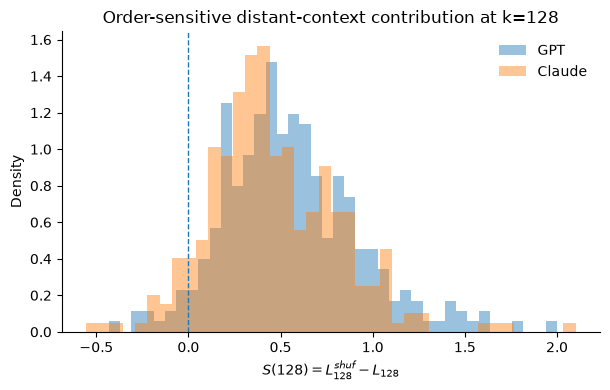

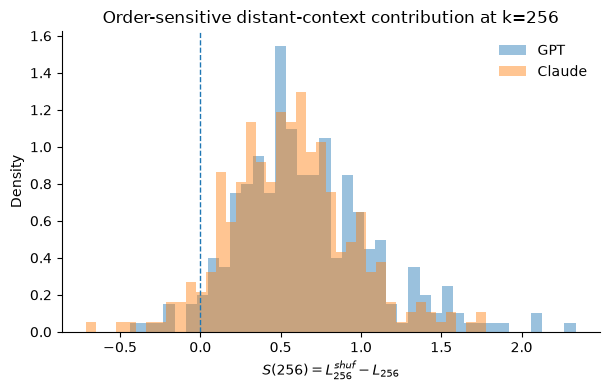

In [11]:
for k in CONTEXT_LENGTHS:
    fig, ax = plt.subplots(figsize=(6.2,4.0))

    for g in ["gpt","claude"]:
        vals = order_null.loc[order_null["generator"] == g, f"order_sensitive_{k}"].dropna()
        ax.hist(vals, bins=40, density=True, alpha=.45, label=("GPT" if g=="gpt" else "Claude"))

    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_xlabel(fr"$S({k}) = L^{{shuf}}_{{{k}}}-L_{{{k}}}$")
    ax.set_ylabel("Density")
    ax.set_title(f"Order-sensitive distant-context contribution at k={k}")
    ax.legend(frameon=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()
    fig.savefig(FIGURES/f"order_sensitive_context_null_{k}.pdf", bbox_inches="tight")
    fig.savefig(FIGURES/f"order_sensitive_context_null_{k}.png", dpi=200, bbox_inches="tight")
    plt.show()


# Interpretation guide

### Strong positive outcome

The strongest pattern would be:

1. \(S(k)>0\) on average;
2. \(S(k)\) differs systematically by generator;
3. \(S(256)\) adds attribution information beyond \((L_8,L_{256})\);
4. \(S(k)\) is not nearly collinear with recurrence frontloading \(F\).

Then the new story becomes:

> Long-context predictive gain contains both a composition-access component and an order-sensitive component. The latter depends on the organization of distant context and provides a complementary structural probe of generated text.

This is substantially more complementary to ordinary context-length probing than \(U(k)\) alone.

### Null outcome

If \(S(k)\approx 0\), then most of the scorer's long-context benefit does not require the original ordering at this block scale.

That is also scientifically useful: it would suggest that the observed \(U(k)\) signal is driven more by distant content availability than by macro-order.

### Important limitation

A block shuffle is one operational null. It destroys some long-range organization while also creating unnatural transitions between blocks. Later robustness should compare multiple block sizes and, ideally, a sentence-order null.
